# 06 - Classification: predict Profit (1) or Loss (0)
We train three models and compare them. The random forest cell takes about a minute.

## Step 1: Load and split (80% train, 20% test)
`stratify=y` keeps the same Profit/Loss mix in train and test.

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

df = pd.read_csv("../data/processed/campaigns_model_ready.csv")

# Revenue is dropped too: ROI is calculated from it, so keeping it would leak the answer
X = df.drop(columns=["Revenue", "Profit_Flag"])
y = df["Profit_Flag"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print("Baseline (always guess Profit):", round(y_test.mean(), 3))

(133332, 37) (33333, 37)
Baseline (always guess Profit): 0.761


## Step 2: Model 1 - Logistic Regression
This model works better when the numbers are on the same scale, so we scale them first.

In [2]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logr = LogisticRegression(max_iter=1000)
logr.fit(X_train_scaled, y_train)
logr_pred = logr.predict(X_test_scaled)

logr_acc = accuracy_score(y_test, logr_pred)
logr_prec = precision_score(y_test, logr_pred)
logr_rec = recall_score(y_test, logr_pred)
logr_f1 = f1_score(y_test, logr_pred)

print("Accuracy:", round(logr_acc, 4), "| Precision:", round(logr_prec, 4), "| Recall:", round(logr_rec, 4), "| F1:", round(logr_f1, 4))

Accuracy: 0.9104 | Precision: 0.9247 | Recall: 0.9605 | F1: 0.9423


## Step 3: Model 2 - Decision Tree
We try a few depths and keep the best test accuracy.

In [3]:
depth_list = [3, 5, 8, 12, 20]

for depth in depth_list:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    score = accuracy_score(y_test, tree.predict(X_test))
    print("max_depth =", depth, "-> test accuracy =", round(score, 4))

max_depth = 3 -> test accuracy = 0.9109
max_depth = 5 -> test accuracy = 0.91
max_depth = 8 -> test accuracy = 0.9078
max_depth = 12 -> test accuracy = 0.9033
max_depth = 20 -> test accuracy = 0.8874


In [4]:
# Use the depth with the best score above (change 3 if another depth scored higher)
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

dt_acc = accuracy_score(y_test, dt_pred)
dt_prec = precision_score(y_test, dt_pred)
dt_rec = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print("Accuracy:", round(dt_acc, 4), "| Precision:", round(dt_prec, 4), "| Recall:", round(dt_rec, 4), "| F1:", round(dt_f1, 4))

Accuracy: 0.9109 | Precision: 0.9314 | Recall: 0.9532 | F1: 0.9422


## Step 4: Model 3 - Random Forest

In [5]:
rf = RandomForestClassifier(n_estimators=50, max_depth=12, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_acc = accuracy_score(y_test, rf_pred)
rf_prec = precision_score(y_test, rf_pred)
rf_rec = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("Accuracy:", round(rf_acc, 4), "| Precision:", round(rf_prec, 4), "| Recall:", round(rf_rec, 4), "| F1:", round(rf_f1, 4))

Accuracy: 0.9101 | Precision: 0.922 | Recall: 0.9634 | F1: 0.9423


## Step 5: Compare the models

In [6]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [logr_acc, dt_acc, rf_acc],
    "Precision": [logr_prec, dt_prec, rf_prec],
    "Recall": [logr_rec, dt_rec, rf_rec],
    "F1": [logr_f1, dt_f1, rf_f1],
}).round(3)

results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.910,0.925,0.961,0.942
1,Decision Tree,0.911,0.931,0.953,0.942
2,Random Forest,0.910,0.922,0.963,0.942


**How to read this:** The baseline of always guessing Profit is about 0.76, so a score near 0.91 is a real improvement. The brief sets a target of 0.95. Here the models stop near 0.91 because the missing piece is the revenue earned per conversion, which none of the allowed inputs can predict. Getting 0.95 would need Revenue or ROI as an input, which is data leakage. Report the real score and explain this in your documentation.

- **Precision:** of the campaigns predicted as Profit, how many really were.
- **Recall:** of the campaigns that really were Profit, how many the model found.
- **F1:** a single score that balances precision and recall.

## Step 6: Confusion matrix (random forest)

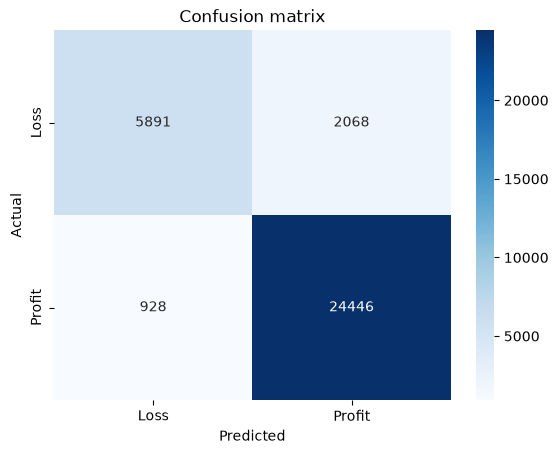

In [7]:
cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Loss", "Profit"], yticklabels=["Loss", "Profit"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.show()

## Step 7: Which inputs matter most?

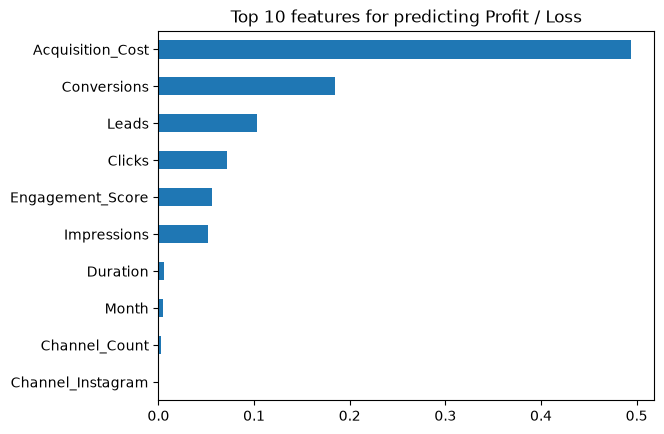

In [8]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 features for predicting Profit / Loss")
plt.show()

## Step 8: Save the best model
The scores are very close. We save the random forest because it needs no scaler. If you pick logistic regression you must also save `scaler`.

In [9]:
best_model = rf

joblib.dump(best_model, "../models/profit_model.pkl")
print("Saved!")

Saved!
